# Figure 5f
The threshold fitness $r_s$ against the probability $f_t$ of fixation by the sampling time. Above $r_s$, island $2$ is the better island to sample. Circles are one sampled individual and squares are a census of the whole island.

In [1]:
import json

import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))
rst = d['r_star']

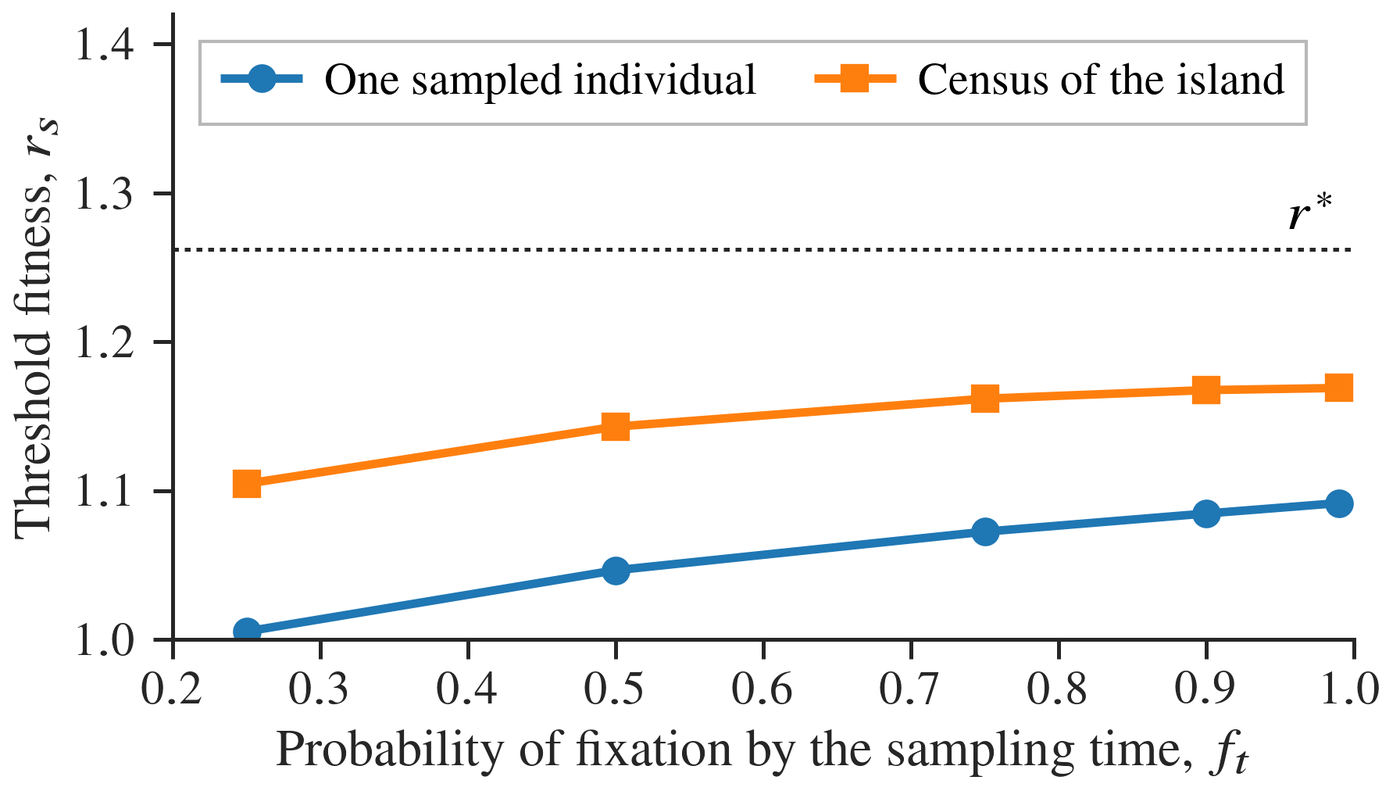

In [2]:
fig = plt.figure(figsize=(7.0, 6.2))
ax = fig.add_axes([0.6, 0.065, 0.36, 0.215])
ax.axhline(rst, color=S.INK, lw=0.6, ls=(0, (1.5, 1.5)))
ax.text(0.985, rst + 0.006, r'$r^*$', fontsize=8, ha='right', va='bottom', transform=ax.get_yaxis_transform())
for key, col, mk, lab in (
  ('crossing', S.BLUE, 'o', 'One sampled individual'),
  ('crossing_all_mutant', S.ORANGE, 's', 'Census of the island'),
):
  keep = [(float(q), d[key][str(q)]) for q in d['quantiles'] if d[key][str(q)] is not None]
  ax.plot([q for q, _ in keep], [x for _, x in keep], color=col, marker=mk, ms=3.4, label=lab)
ax.set_xlim(0.2, 1.0)
ax.set_ylim(1.0, 1.42)
ax.set_yticks([1.0, 1.1, 1.2, 1.3, 1.4])
ax.set_xlabel(r'Probability of fixation by the sampling time, $f_t$')
ax.set_ylabel(r'Threshold fitness, $r_s$')
S.legend(ax, loc='upper left', ncol=2, columnspacing=1.2)
S.save_panel(fig, 'f')